In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

In [3]:
matches.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [4]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [5]:
matches.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   object 
 2   city             1044 non-null   object 
 3   date             1095 non-null   object 
 4   match_type       1095 non-null   object 
 5   player_of_match  1090 non-null   object 
 6   venue            1095 non-null   object 
 7   team1            1095 non-null   object 
 8   team2            1095 non-null   object 
 9   toss_winner      1095 non-null   object 
 10  toss_decision    1095 non-null   object 
 11  winner           1090 non-null   object 
 12  result           1095 non-null   object 
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   object 
 17  method        

In [6]:
matches.isnull().sum()

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64

In [7]:
deliveries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

In [8]:
deliveries.isnull().sum()

match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

In [9]:
print("Duplicate rows in matches:", matches.duplicated().sum())
print("Duplicate rows in deliveries:", deliveries.duplicated().sum())

Duplicate rows in matches: 0
Duplicate rows in deliveries: 0


In [3]:
matches['date'] = pd.to_datetime(matches['date'])


In [13]:
matches['date'].dtype

dtype('<M8[ns]')

In [14]:
matches = matches.drop_duplicates()
deliveries = deliveries.drop_duplicates()

In [15]:
matches.isnull().sum()

id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64

In [4]:
matches['city'] = matches['city'].fillna('Unknown')

In [17]:
matches['city'].isnull().sum()

np.int64(0)

In [13]:
print("Total number of matches:", matches.shape[0])
print("Total number of seasons:", matches['season'].nunique())
print("Total number of teams:", len(pd.unique(matches[['team1', 'team2']].values.ravel())))
print("Total number of venues:", matches['venue'].nunique())

Total number of matches: 1095
Total number of seasons: 17
Total number of teams: 19
Total number of venues: 58


In [5]:
matches_per_season = matches['season'].value_counts().sort_index()
matches_per_season

season
2007/08    58
2009       57
2009/10    60
2011       73
2012       74
2013       76
2014       60
2015       59
2016       60
2017       59
2018       60
2019       60
2020/21    60
2021       60
2022       74
2023       74
2024       71
Name: count, dtype: int64

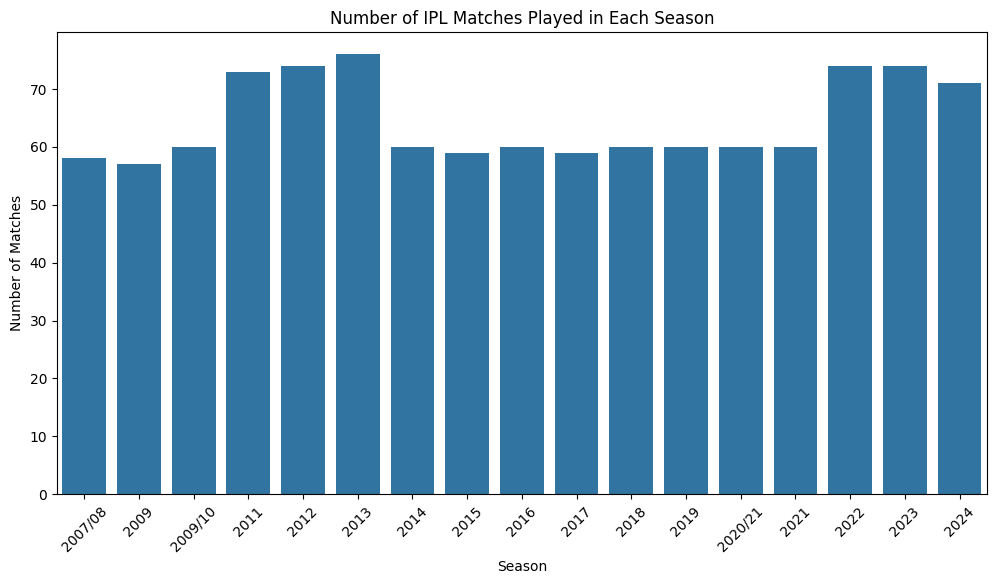

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=matches_per_season.index,
    y=matches_per_season.values
)

plt.title('Number of IPL Matches Played in Each Season')
plt.xlabel('Season')
plt.ylabel('Number of Matches')
plt.xticks(rotation=45)
plt.savefig("Number of IPL Matches Played in Each Season.png")
plt.show()

In [6]:
team_wins = matches['winner'].value_counts()
team_wins

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    116
Rajasthan Royals               112
Sunrisers Hyderabad             88
Kings XI Punjab                 88
Delhi Daredevils                67
Delhi Capitals                  48
Deccan Chargers                 29
Gujarat Titans                  28
Punjab Kings                    24
Lucknow Super Giants            24
Gujarat Lions                   13
Pune Warriors                   12
Rising Pune Supergiant          10
Royal Challengers Bengaluru      7
Kochi Tuskers Kerala             6
Rising Pune Supergiants          5
Name: count, dtype: int64

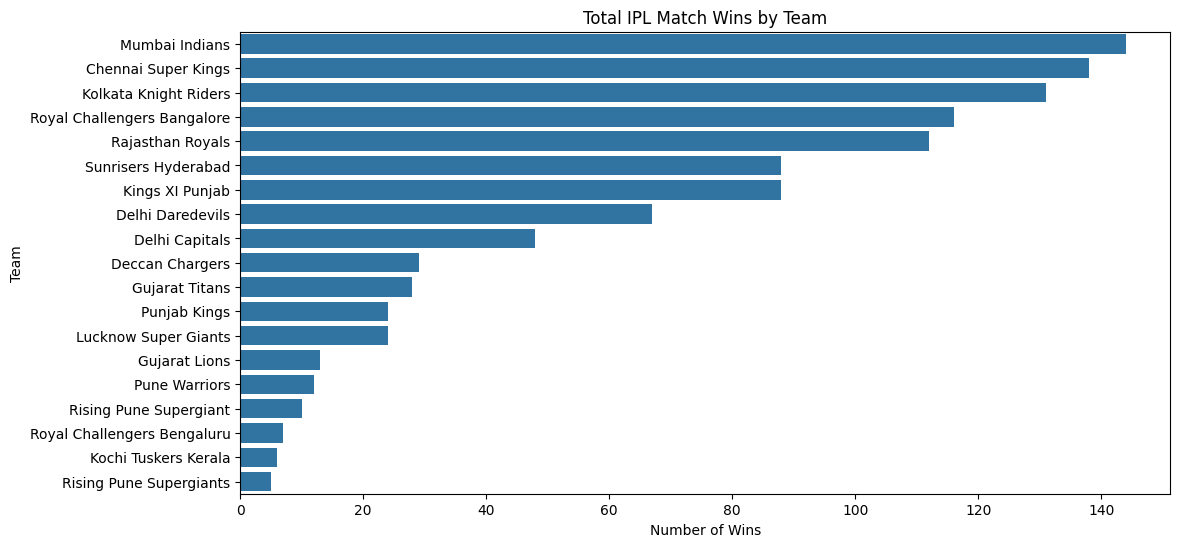

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_wins.values,
    y=team_wins.index
)

plt.title('Total IPL Match Wins by Team')
plt.xlabel('Number of Wins')
plt.ylabel('Team')
plt.savefig("Total IPL Match Wins by Team.png")
plt.show()

In [7]:
toss_decision = matches['toss_decision'].value_counts()
toss_decision

toss_decision
field    704
bat      391
Name: count, dtype: int64

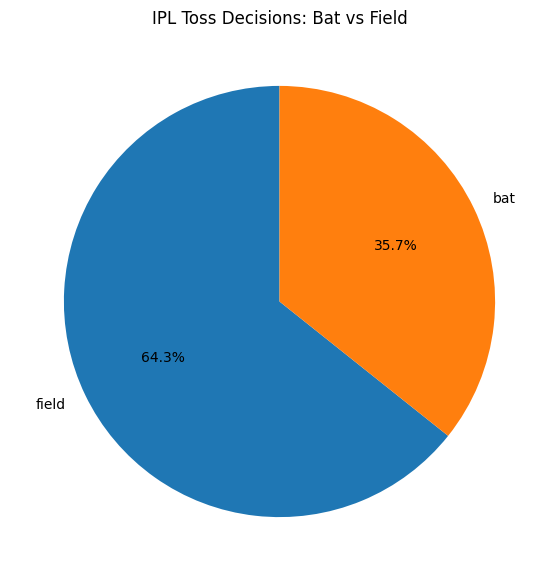

In [29]:
plt.figure(figsize=(7, 7))

plt.pie(
    toss_decision.values,
    labels=toss_decision.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('IPL Toss Decisions: Bat vs Field')
plt.savefig("IPL Toss Decisions.png")
plt.show()

In [8]:
toss_match = matches[matches['winner'].notna()].copy()

toss_match['toss_match_winner'] = (
    toss_match['toss_winner'] == toss_match['winner']
)

toss_result = toss_match['toss_match_winner'].value_counts()
toss_result

toss_match_winner
True     554
False    536
Name: count, dtype: int64

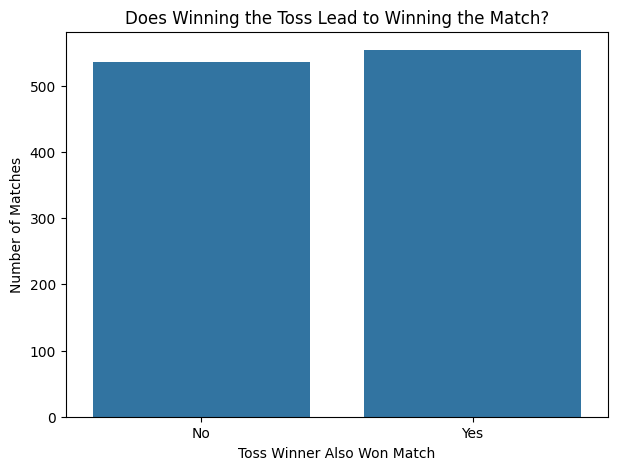

In [31]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=toss_match,
    x='toss_match_winner'
)

plt.title('Does Winning the Toss Lead to Winning the Match?')
plt.xlabel('Toss Winner Also Won Match')
plt.ylabel('Number of Matches')

plt.xticks([0, 1], ['No', 'Yes'])
plt.savefig("Toss VS Match Winners")
plt.show()

In [9]:
top_venues = matches['venue'].value_counts().head(10)
top_venues

venue
Eden Gardens                                  77
Wankhede Stadium                              73
M Chinnaswamy Stadium                         65
Feroz Shah Kotla                              60
Rajiv Gandhi International Stadium, Uppal     49
MA Chidambaram Stadium, Chepauk               48
Sawai Mansingh Stadium                        47
Dubai International Cricket Stadium           46
Wankhede Stadium, Mumbai                      45
Punjab Cricket Association Stadium, Mohali    35
Name: count, dtype: int64

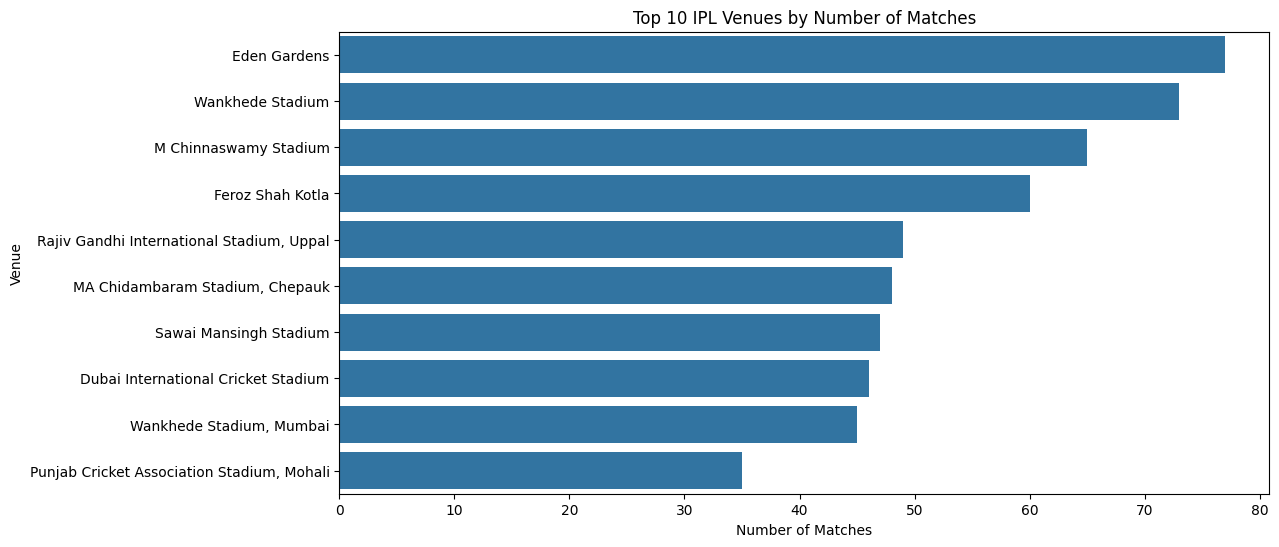

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_venues.values,
    y=top_venues.index
)

plt.title('Top 10 IPL Venues by Number of Matches')
plt.xlabel('Number of Matches')
plt.ylabel('Venue')
plt.savefig("Top 10 IPL Venues.png")
plt.show()

In [10]:
top_players = matches['player_of_match'].value_counts().head(10)
top_players

player_of_match
AB de Villiers    25
CH Gayle          22
RG Sharma         19
V Kohli           18
DA Warner         18
MS Dhoni          17
YK Pathan         16
RA Jadeja         16
SR Watson         16
AD Russell        15
Name: count, dtype: int64

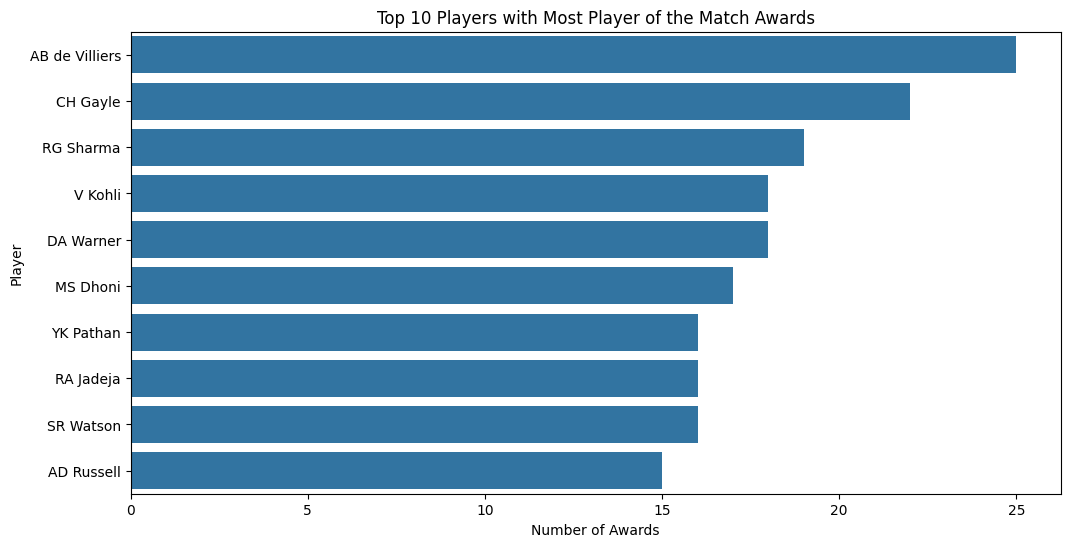

In [37]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_players.values,
    y=top_players.index
)

plt.title('Top 10 Players with Most Player of the Match Awards')
plt.xlabel('Number of Awards')
plt.ylabel('Player')
plt.savefig("Top 10 Players with Most Player of the Match Awards.png")
plt.show()

In [36]:
top_batsmen = (
    deliveries.groupby('batter')['batsman_runs']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_batsmen

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
Name: batsman_runs, dtype: int64

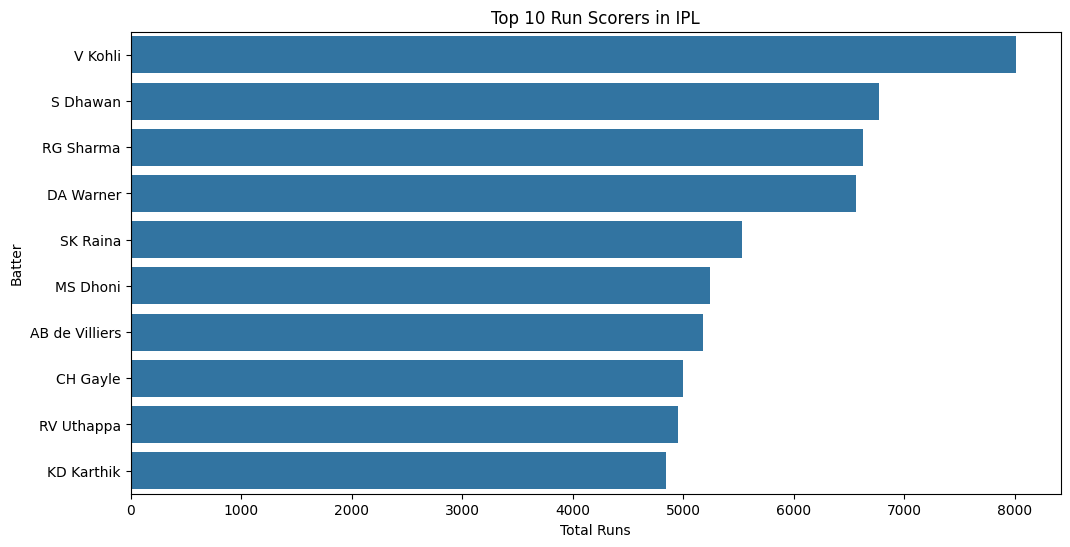

In [38]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_batsmen.values,
    y=top_batsmen.index
)

plt.title('Top 10 Run Scorers in IPL')
plt.xlabel('Total Runs')
plt.ylabel('Batter')
plt.savefig("Top 10 Run Scorers in IPL.png")
plt.show()

In [39]:
top_bowlers = (
    deliveries[deliveries['is_wicket'] == 1]
    .groupby('bowler')
    .size()
    .sort_values(ascending=False)
    .head(10)
)

top_bowlers

bowler
YS Chahal     213
DJ Bravo      207
PP Chawla     201
SP Narine     200
R Ashwin      198
B Kumar       195
SL Malinga    188
A Mishra      183
JJ Bumrah     182
RA Jadeja     169
dtype: int64

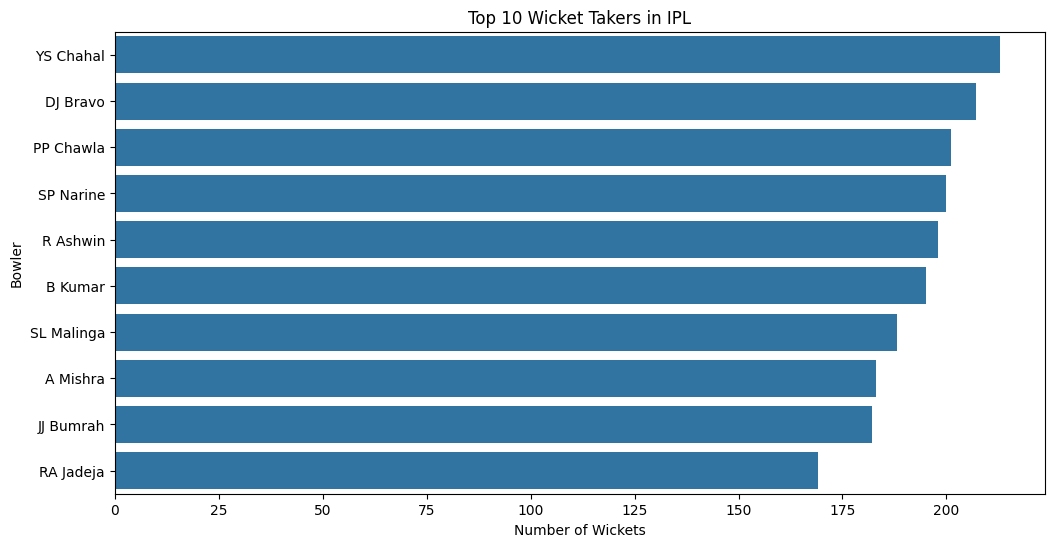

In [41]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_bowlers.values,
    y=top_bowlers.index
)

plt.title('Top 10 Wicket Takers in IPL')
plt.xlabel('Number of Wickets')
plt.ylabel('Bowler')
plt.savefig("Top 10 Wicket Takers in IPL.png")
plt.show()

In [42]:
team_runs = (
    deliveries.groupby('batting_team')['total_runs']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

team_runs

batting_team
Mumbai Indians                 42176
Kolkata Knight Riders          39331
Chennai Super Kings            38629
Royal Challengers Bangalore    37692
Rajasthan Royals               34747
Kings XI Punjab                30064
Sunrisers Hyderabad            29071
Delhi Daredevils               24296
Delhi Capitals                 14900
Deccan Chargers                11463
Name: total_runs, dtype: int64

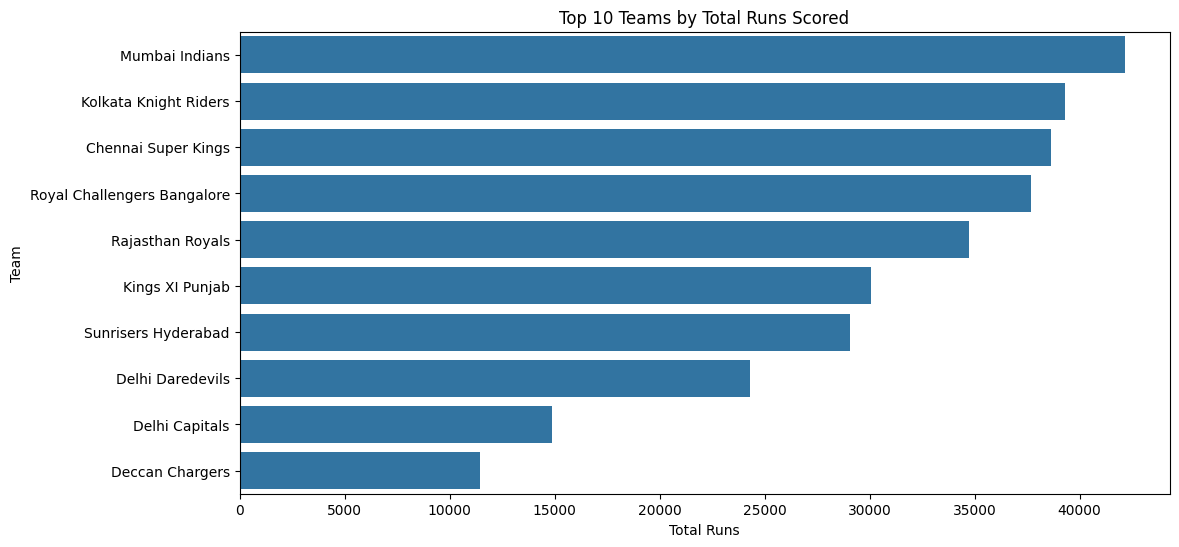

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_runs.values,
    y=team_runs.index
)

plt.title('Top 10 Teams by Total Runs Scored')
plt.xlabel('Total Runs')
plt.ylabel('Team')
plt.savefig("Top 10 Teams by Total Runs Scored.png")
plt.show()

In [44]:
# Add season information to deliveries
deliveries_with_season = deliveries.merge(
    matches[['id', 'season']],
    left_on='match_id',
    right_on='id',
    how='left'
)

season_runs = (
    deliveries_with_season.groupby('season')['total_runs']
    .sum()
)

season_runs

season
2007/08    17937
2009       16353
2009/10    18883
2011       21154
2012       22453
2013       22602
2014       18931
2015       18353
2016       18862
2017       18786
2018       19901
2019       19434
2020/21    19416
2021       18637
2022       24395
2023       25688
2024       25971
Name: total_runs, dtype: int64

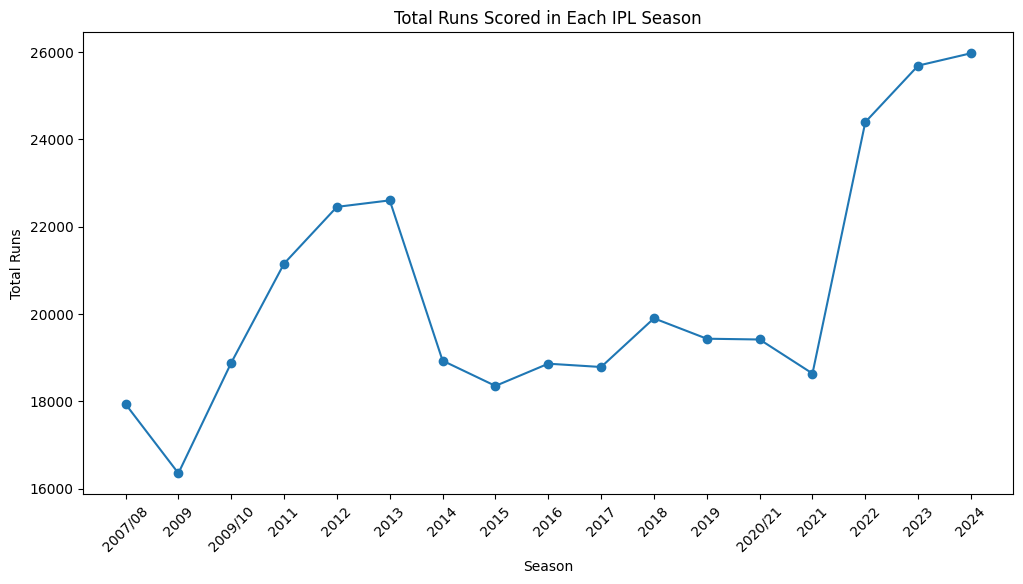

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    season_runs.index.astype(str),
    season_runs.values,
    marker='o'
)

plt.title('Total Runs Scored in Each IPL Season')
plt.xlabel('Season')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.savefig("Total Runs Scored in Each IPL Season.png")
plt.show()

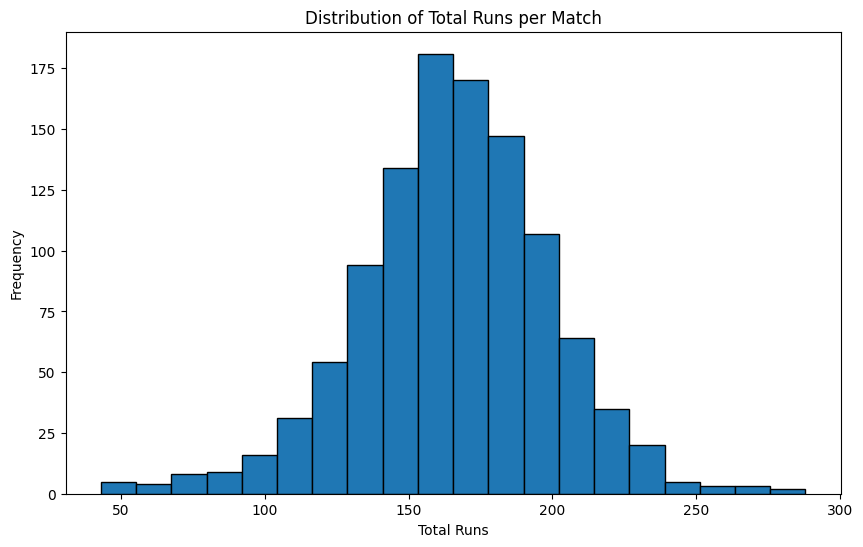

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    matches['target_runs'].dropna(),
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Total Runs per Match')
plt.xlabel('Total Runs')
plt.ylabel('Frequency')
plt.savefig("Histogram - Distribution of Total Runs per Match.png")
plt.show()

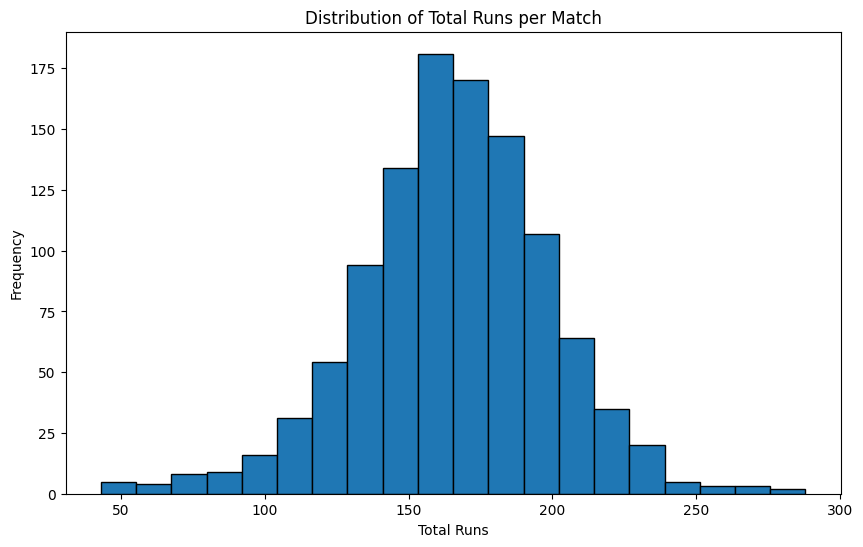

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    matches['target_runs'].dropna(),
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Total Runs per Match')
plt.xlabel('Total Runs')
plt.ylabel('Frequency')
plt.savefig("Histogram - Distribution of Total Runs per Match.png")
plt.show()

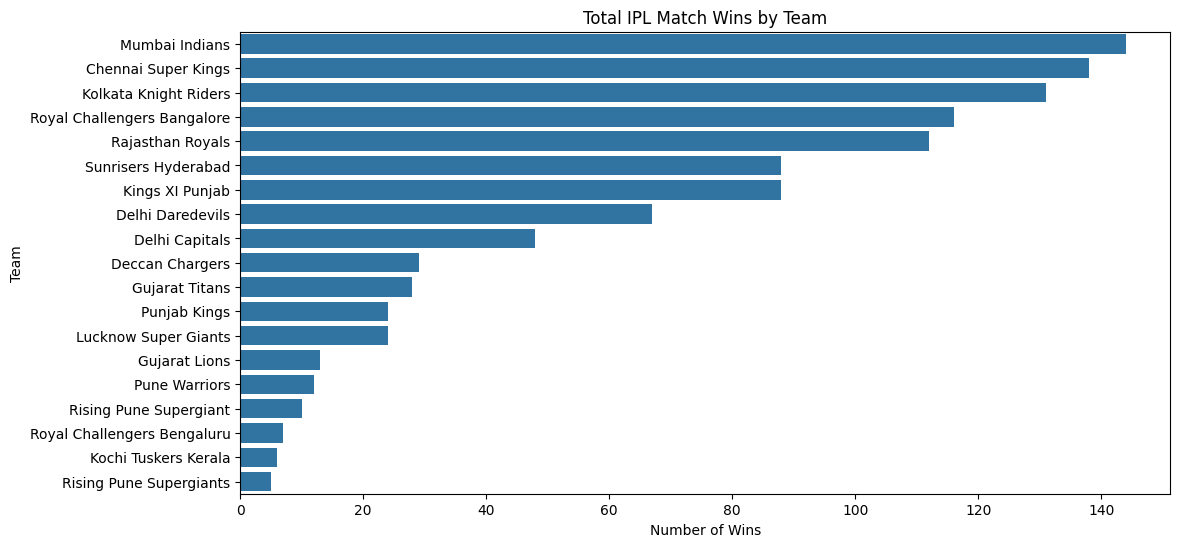

In [35]:
team_wins = matches['winner'].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_wins.values,
    y=team_wins.index
)

plt.title('Total IPL Match Wins by Team')
plt.xlabel('Number of Wins')
plt.ylabel('Team')
plt.savefig("Bar Chart - Total IPL Match Wins by Team")
plt.show()

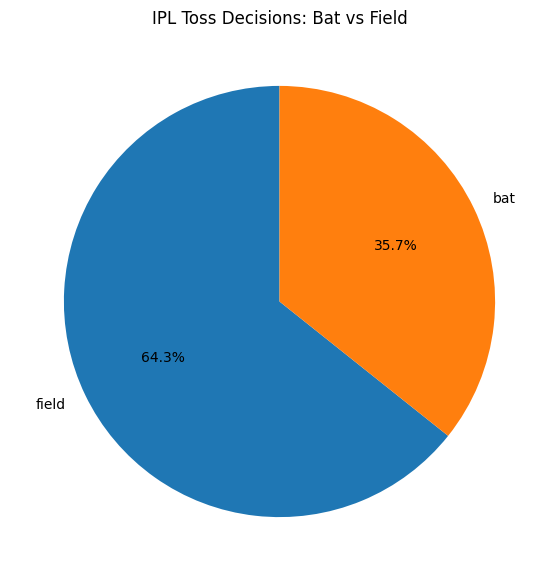

In [34]:
toss_decision = matches['toss_decision'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    toss_decision.values,
    labels=toss_decision.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('IPL Toss Decisions: Bat vs Field')
plt.savefig("Pie Chart –Bat vs Field.png")
plt.show()

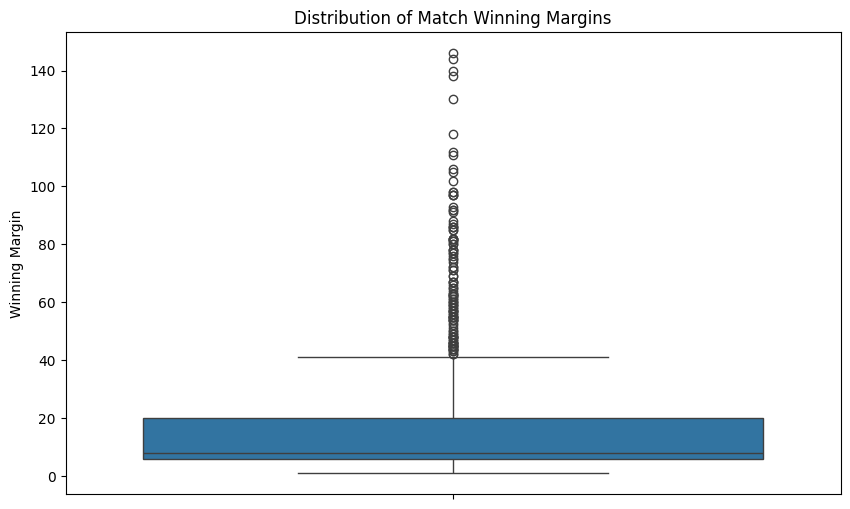

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    y=matches['result_margin'].dropna()
)

plt.title('Distribution of Match Winning Margins')
plt.ylabel('Winning Margin')
plt.savefig("Box Plot – Distribution of Match Winning Margins.png")
plt.show()

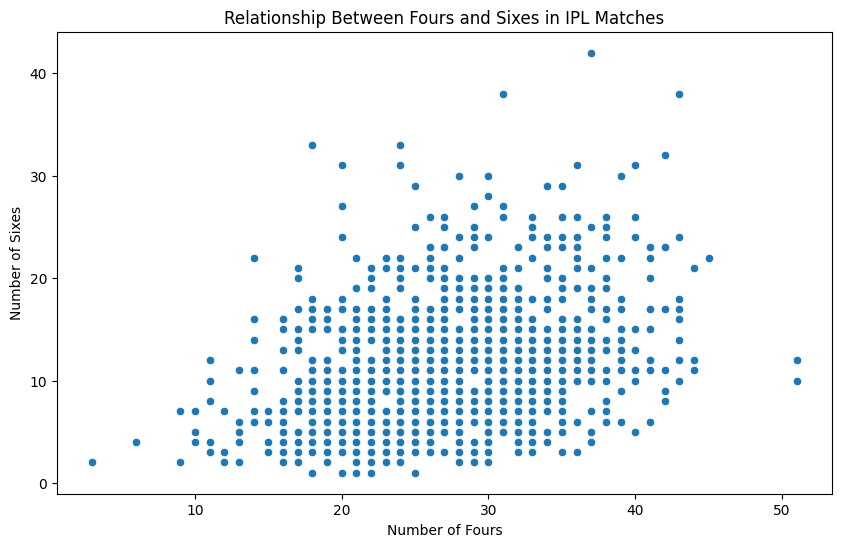

In [22]:
match_boundaries = deliveries.groupby('match_id').agg(
    Fours=('batsman_runs', lambda x: (x == 4).sum()),
    Sixes=('batsman_runs', lambda x: (x == 6).sum())
).reset_index()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=match_boundaries,
    x='Fours',
    y='Sixes'
)

plt.title('Relationship Between Fours and Sixes in IPL Matches')
plt.xlabel('Number of Fours')
plt.ylabel('Number of Sixes')
plt.savefig("Scatter Plot – Fours vs Sixes in IPL Matches.png")
plt.show()

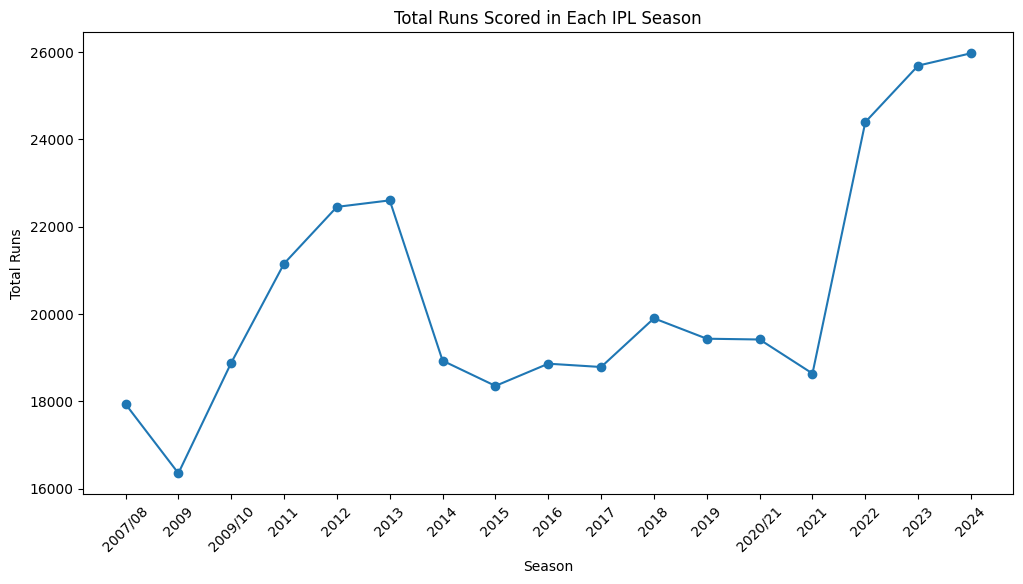

In [23]:
deliveries_with_season = deliveries.merge(
    matches[['id', 'season']],
    left_on='match_id',
    right_on='id',
    how='left'
)

season_runs = (
    deliveries_with_season.groupby('season')['total_runs']
    .sum()
)

plt.figure(figsize=(12, 6))

plt.plot(
    season_runs.index.astype(str),
    season_runs.values,
    marker='o'
)

plt.title('Total Runs Scored in Each IPL Season')
plt.xlabel('Season')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.savefig("Line Chart – Total Runs Scored in Each IPL Season.png")
plt.show()

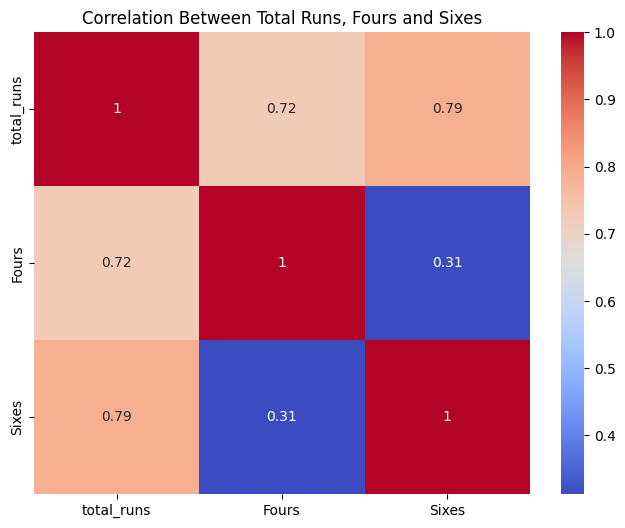

In [24]:
# Calculate total runs per match
match_runs = deliveries.groupby('match_id')['total_runs'].sum().reset_index()

# Calculate fours per match
match_fours = (
    deliveries[deliveries['batsman_runs'] == 4]
    .groupby('match_id')
    .size()
    .reset_index(name='Fours')
)

# Calculate sixes per match
match_sixes = (
    deliveries[deliveries['batsman_runs'] == 6]
    .groupby('match_id')
    .size()
    .reset_index(name='Sixes')
)

# Merge the data
match_stats = match_runs.merge(
    match_fours,
    on='match_id',
    how='left'
).merge(
    match_sixes,
    on='match_id',
    how='left'
)

match_stats = match_stats.fillna(0)

# Create correlation matrix
correlation = match_stats[
    ['total_runs', 'Fours', 'Sixes']
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Between Total Runs, Fours and Sixes')
plt.savefig("Heatmap – Correlation Between Numerical Variables.png")
plt.show()

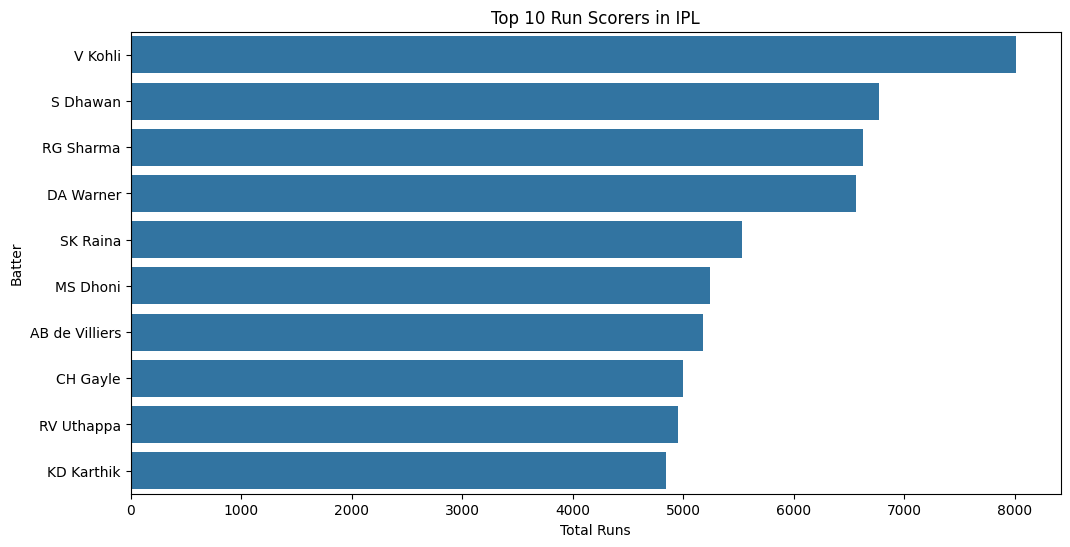

In [20]:
top_batsmen = (
    deliveries.groupby('batter')['batsman_runs']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_batsmen.values,
    y=top_batsmen.index
)

plt.title('Top 10 Run Scorers in IPL')
plt.xlabel('Total Runs')
plt.ylabel('Batter')
plt.savefig("Bar Chart – Top 10 Run Scorers in IPL")
plt.show()